# Exercice 1 — MNIST au-delà de 97 % · **version à trous**

**Hands-On ML, chapitre 3, exercice 1** · carnet CS229, bloc **B14**, étape 13 (option)

> *Essayez de construire un classifieur pour MNIST qui atteigne plus de 97 % d'accuracy sur le
> test set. Indice : `KNeighborsClassifier` fonctionne bien pour cette tâche ; il suffit de
> trouver de bonnes valeurs pour les hyperparamètres `weights` et `n_neighbors`.*

---

## Comment utiliser ce notebook

Les cellules marquées **`# TODO`** contiennent des `...` à remplacer. Chacune est suivie d'une
**cellule de vérification** qui s'exécute seule et vous dit si c'est juste.

```
# Verification - ne modifiez pas cette cellule
assert ...
print("OK")
```

Si l'assertion passe, continuez. Si elle échoue, le message vous dit quoi corriger.

Les cellules sans `# TODO` sont déjà complètes : ce sont des imports, de l'affichage, ou de la
plomberie qui n'est pas l'objet de l'exercice. Exécutez-les telles quelles.

Le corrigé est dans `B14_ex1_mnist_97.ipynb`. Ne l'ouvrez qu'après avoir buté dix minutes sur un
trou — c'est là que l'apprentissage se fait.

**8 trous** dans ce notebook.

## Ce que l'exercice teste vraiment

1. Le **k-nearest neighbors** n'a pas de phase d'entraînement : il mémorise et paie à la
   prédiction.
2. Un **grid search se valide sur un sous-échantillon** avant d'être lancé en entier.
3. Le **test set ne se touche qu'une fois**, tout à la fin (point **B13-6**).

## Notation

Carnet et CS229 : $n$ exemples, $d$ features. Hands-On ML écrit $m$ exemples et $n$ features.
Ici $n = 60\,000$ et $d = 784$.

---
## 1. Environnement

*Cellule complète — exécutez-la.*

In [7]:
import time

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
rng = np.random.default_rng(SEED)

plt.rcParams["figure.dpi"] = 110

print("numpy", np.__version__)

numpy 2.3.5


---
## 2. Chargement de MNIST

`fetch_openml` télécharge environ 55 Mo la première fois, puis met en cache dans
`~/scikit_learn_data`.

- `as_frame=False` renvoie des tableaux NumPy plutôt qu'un DataFrame pandas. Pour 70 000 images
  de 784 pixels, le DataFrame est inutilement lourd.
- `parser="auto"` évite un avertissement de dépréciation.

*Cellule complète.*

In [8]:
mnist = fetch_openml("mnist_784", as_frame=False, parser="auto")

X, y = mnist.data, mnist.target
print("X :", X.shape, X.dtype)
print("y :", y.shape, y.dtype, "->", y[:10])

X : (70000, 784) int64
y : (70000,) object -> ['5' '0' '4' '1' '9' '2' '1' '3' '1' '4']


### Trou 1 — conversion des types

Regardez ce que la cellule précédente a affiché. Deux problèmes :

`y` contient des **chaînes de caractères** (`'5'`, `'0'`, ...), pas des entiers. Scikit-learn s'en
accommode pour la classification, mais un test comme `y_pred == 7` renverra `False` partout,
silencieusement.

`X` est en **`float64`** : $70\,000 \times 784 \times 8$ octets, soit 440 Mo. Or les pixels sont
des entiers entre 0 et 255, qui tiennent sur **un seul octet**.

In [9]:
# TODO (trou 1) - Convertir les deux tableaux dans le bon type.
#   y : entiers (les etiquettes vont de 0 a 9)
#   X : entiers sur un octet (les pixels vont de 0 a 255)
#   Indice : np.uint8 est le type entier non signe sur 8 bits.
#            La methode de conversion d'un tableau NumPy est .astype(...)

y = y.astype(np.uint8)
X = X.astype(np.uint8)       # <-- a completer

print("y :", y.dtype, "->", y[:10])
print("pixels : de", X.min(), "a", X.max())
print(f"memoire X : {X.nbytes / 1e6:.0f} Mo")

y : uint8 -> [5 0 4 1 9 2 1 3 1 4]
pixels : de 0 a 255
memoire X : 55 Mo


In [10]:
# Verification - ne modifiez pas cette cellule
assert y.dtype == np.uint8, f"y doit etre en uint8, pas {y.dtype}"
assert X.dtype == np.uint8, f"X doit etre en uint8, pas {X.dtype}"
assert y[0] == 5, "l'etiquette de la premiere image doit valoir l'entier 5"
assert X.nbytes < 100e6, "X devrait occuper environ 55 Mo"
print("Trou 1 : OK")

Trou 1 : OK


---
## 3. Train / test split

MNIST est **déjà séparé** : les 60 000 premières images forment le training set officiel, les
10 000 dernières le test set. On n'utilise donc **pas** `train_test_split`.

Deux raisons de respecter ce découpage :

- il est déjà mélangé, donc pas besoin de `shuffle` ;
- tous les résultats publiés depuis 1998 utilisent exactement ce découpage, donc votre 97 % est
  comparable à la littérature.

### Trou 2 — le découpage

In [11]:
# TODO (trou 2) - Decouper X et y en training set et test set.
#   Les 60 000 PREMIERES lignes -> train
#   Les 10 000 DERNIERES        -> test
#   Indice : un simple slicing NumPy suffit, X[:k] et X[k:]

X_train, X_test = X[:60000], X[-10000:]      
y_train, y_test = y[:60000], y[-10000:]      

print("train :", X_train.shape, "  test :", X_test.shape)

train : (60000, 784)   test : (10000, 784)


In [12]:
# Verification - ne modifiez pas cette cellule
assert X_train.shape == (60000, 784), f"X_train devrait etre (60000, 784), pas {X_train.shape}"
assert X_test.shape == (10000, 784), f"X_test devrait etre (10000, 784), pas {X_test.shape}"
assert len(y_train) == 60000 and len(y_test) == 10000, "les etiquettes ne suivent pas"
assert np.array_equal(X_train[0], X[0]), "le train doit commencer au debut de X"
assert np.array_equal(X_test[0], X[60000]), "le test doit commencer a l'indice 60000"
assert y_train[0] == y[0] and y_test[0] == y[60000], "X et y doivent etre decoupes au meme endroit"
print("Trou 2 : OK")

Trou 2 : OK


In [13]:
print("repartition des classes dans le training set :")
for chiffre, compte in enumerate(np.bincount(y_train)):
    print(f"  {chiffre} : {compte}")

repartition des classes dans le training set :
  0 : 5923
  1 : 6742
  2 : 5958
  3 : 6131
  4 : 5842
  5 : 5421
  6 : 5918
  7 : 6265
  8 : 5851
  9 : 5949


Les classes sont à peu près équilibrées (entre 5 400 et 6 700 exemples chacune). On peut donc
utiliser l'**accuracy** sans arrière-pensée.

C'est un cas rare, et c'est exactement ce que dit le point **B14-9** : dès que les classes sont
déséquilibrées, l'accuracy devient trompeuse et il faut passer à precision, recall, F1 ou AUC.

---
## 4. Un coup d'œil aux données

On ne lance jamais un modèle sur des données qu'on n'a pas regardées.

*Cellule complète.*

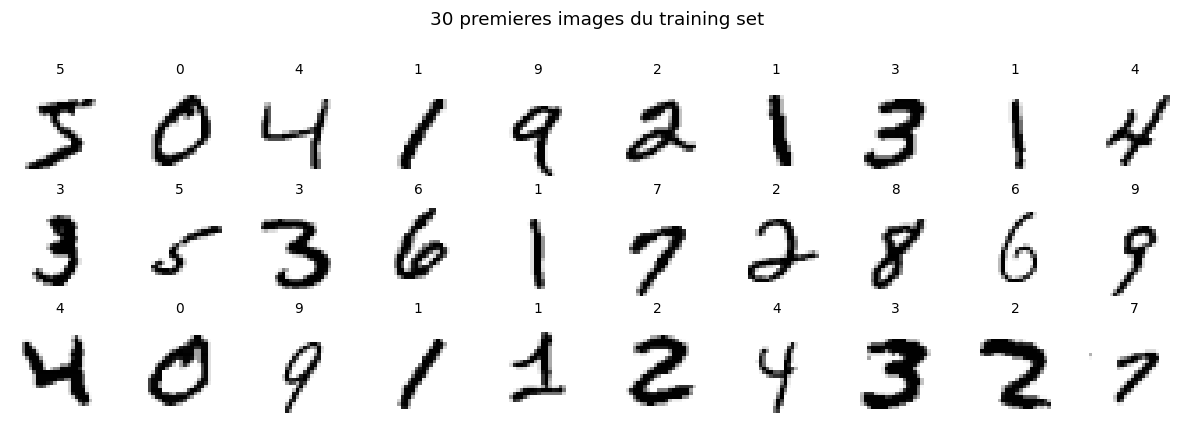

In [14]:
fig, axes = plt.subplots(3, 10, figsize=(11, 3.8))
for ax, img, label in zip(axes.ravel(), X_train[:30], y_train[:30]):
    ax.imshow(img.reshape(28, 28), cmap="binary")
    ax.set_title(int(label), fontsize=9)
    ax.axis("off")
fig.suptitle("30 premieres images du training set", y=1.02)
plt.tight_layout()
plt.show()

**Question à vous poser avant de continuer** (pas de code, juste y réfléchir) :

Observez que les chiffres sont **centrés** dans leur cadre et **normalisés en taille**. En quoi
est-ce décisif pour un algorithme qui compare les images par la distance euclidienne pixel à
pixel ?

$$\lVert x - x^{(i)} \rVert_{2} = \sqrt{\sum_{j=1}^{d} \left(x_{j} - x_{j}^{(i)}\right)^{2}}$$

Réponse à la fin de la section 5. C'est aussi tout le sujet de l'exercice 2.

---
## 5. Baseline : k-NN par défaut

Avant d'optimiser quoi que ce soit, il faut un point de départ. On entraîne un
`KNeighborsClassifier` avec ses paramètres par défaut (`n_neighbors=5`, `weights="uniform"`) sur
un **sous-échantillon de 10 000 exemples**, pour que ce soit rapide.

Rappel du fonctionnement : pour classer une image $x \in \mathbb{R}^{d}$, l'algorithme calcule sa
distance à **tous** les exemples mémorisés, garde les $k$ plus proches, et fait voter leurs
étiquettes. Avec $n$ exemples mémorisés et $d = 784$ features, chaque prédiction coûte
$O(n \cdot d)$ en version naïve.

### Trou 3 — entraîner et chronométrer

Le chronométrage n'est pas décoratif : le rapport entre les deux durées est **l'enseignement
principal de cette section**.

In [20]:
N_SUB = 10_000
X_sub, y_sub = X_train[:N_SUB], y_train[:N_SUB]

knn_base = KNeighborsClassifier()

# TODO (trou 3) - Entrainer le modele sur le sous-echantillon, puis predire
#   sur les 2000 PREMIERES images du test set. Chaque etape est chronometree.
#   Indice : les methodes sont .fit(X, y) et .predict(X)

t0 = time.perf_counter()
model=knn_base.fit(X_sub, y_sub)                                 # <-- a completer : entrainement
t_fit = time.perf_counter() - t0

t0 = time.perf_counter()
y_pred_sub = knn_base.predict(X_test[:2000])                      # <-- a completer : prediction
t_pred = time.perf_counter() - t0

print(f"fit     : {t_fit:7.3f} s  (10 000 exemples memorises)")
print(f"predict : {t_pred:7.3f} s  (2 000 images a classer)")
print(f"\naccuracy sur cet echantillon : {accuracy_score(y_test[:2000], y_pred_sub):.4f}")

fit     :   0.010 s  (10 000 exemples memorises)
predict :   0.486 s  (2 000 images a classer)

accuracy sur cet echantillon : 0.9205


In [21]:
# Verification - ne modifiez pas cette cellule
from sklearn.exceptions import NotFittedError
from sklearn.utils.validation import check_is_fitted

try:
    check_is_fitted(knn_base)
except NotFittedError:
    raise AssertionError("knn_base n'a pas ete entraine : appelez .fit(X_sub, y_sub)")

assert len(y_pred_sub) == 2000, f"y_pred_sub doit contenir 2000 predictions, pas {len(y_pred_sub)}"
assert accuracy_score(y_test[:2000], y_pred_sub) > 0.9, \
    "accuracy trop basse : avez-vous bien predit sur X_test[:2000] ?"
assert t_pred > t_fit, \
    "le predict devrait etre PLUS LENT que le fit pour un k-NN - verifiez vos chronos"
print("Trou 3 : OK")
print(f"\nLe predict est {t_pred/max(t_fit, 1e-6):.0f}x plus lent que le fit.")

Trou 3 : OK

Le predict est 47x plus lent que le fit.


Voilà la signature d'un **non-parametric algorithm** : il ne résume pas les données en paramètres,
il les garde. Le `fit` ne fait que ranger les points dans une structure de recherche (`KDTree` ou
`BallTree`) ; toute la dépense est reportée sur le `predict`.

**Réponse à la question de la section 4** : parce que les chiffres sont centrés et normalisés,
deux images du même chiffre sont effectivement proches au sens de cette distance. Si les chiffres
étaient décalés de quelques pixels, deux « 7 » identiques mais décalés se retrouveraient très
éloignés, et le k-NN s'effondrerait. C'est la nuance du point **B17-15** : le k-NN n'est pas
magique, il est **bien conditionné ici**.

---
## 6. Combien de temps le grid search va-t-il coûter ?

On extrapole **avant** de lancer quoi que ce soit de long. Le coût de prédiction croît
linéairement avec le nombre d'exemples mémorisés **et** avec le nombre de requêtes :

$$t \;\approx\; t_{\text{mesuré}} \times \frac{n_{\text{train}}}{n_{\text{train}}^{\text{réf}}}
\times \frac{n_{\text{requêtes}}}{n_{\text{requêtes}}^{\text{réf}}}$$

### Trou 4 — la fonction d'extrapolation

In [22]:
# TODO (trou 4) - Ecrire l'extrapolation lineaire decrite par la formule ci-dessus.
#   t_ref       : duree mesuree sur la configuration de reference
#   n_train     : nombre d'exemples memorises dans la configuration visee
#   n_query     : nombre de requetes dans la configuration visee
#   Les deux derniers arguments donnent la configuration de reference.

def estime_duree(t_ref, n_train, n_query, n_train_ref=N_SUB, n_query_ref=2000):
    t = t_ref * (n_train/n_train_ref)*(n_query/n_query_ref)
    return t 

In [23]:
# Verification - ne modifiez pas cette cellule
assert estime_duree(1.0, 10_000, 2_000) == 1.0, "la configuration de reference doit rendre t_ref"
assert estime_duree(1.0, 20_000, 2_000) == 2.0, "doubler le train doit doubler la duree"
assert estime_duree(1.0, 10_000, 4_000) == 2.0, "doubler les requetes doit doubler la duree"
assert estime_duree(1.0, 20_000, 4_000) == 4.0, "les deux facteurs se multiplient"
assert estime_duree(3.0, 5_000, 1_000) == 0.75, "la fonction doit aussi savoir reduire"
print("Trou 4 : OK")

Trou 4 : OK


In [25]:
t_full = estime_duree(t_pred, n_train=60_000, n_query=10_000)
print(f"predict final (60k memorises, 10k requetes) : ~{t_full:6.1f} s")

# Un GridSearchCV avec cv=3 et G combinaisons effectue G*3 entrainements.
# Chaque fold memorise 2/3 du train (40 000) et predit sur 1/3 (20 000).
G = 6
t_grid = G * 3 * estime_duree(t_pred, n_train=40_000, n_query=20_000)
print(f"\ngrid search ({G} combinaisons x 3 folds) :")
print(f"  sur 1 coeur  : ~{t_grid/60:6.1f} min")
print(f"  sur 8 coeurs : ~{t_grid/60/8:6.1f} min")

predict final (60k memorises, 10k requetes) : ~  14.6 s

grid search (6 combinaisons x 3 folds) :
  sur 1 coeur  : ~   5.8 min
  sur 8 coeurs : ~   0.7 min


Ces chiffres sont approximatifs — les structures d'arbre utilisées par scikit-learn ne sont pas
exactement linéaires en $n$ — mais l'ordre de grandeur est juste.

**Si l'estimation annonce plusieurs heures**, réduisez la grille du trou 5 avant de lancer : par
exemple `n_neighbors` dans `[4, 5]` et `weights` fixé à `"distance"`.

---
## 7. Grid search, étape 1 : valider le code sur un sous-échantillon

**Ne sautez pas cette étape.** Elle coûte deux minutes et vous évite de découvrir une faute de
frappe après quarante minutes d'attente.

### Trou 5 — la grille et l'objet de recherche

Un `param_grid` est une **liste de dictionnaires**. Chaque clé est un nom d'hyperparamètre du
modèle, chaque valeur est la liste des valeurs à essayer. `GridSearchCV` teste toutes les
combinaisons du produit cartésien.

In [45]:
# TODO (trou 5a) - Construire la grille d'hyperparametres.
#   n_neighbors : essayer 3, 4 et 5
#   weights     : essayer "uniform" et "distance"
#   Format : une liste contenant UN dictionnaire {nom: [valeurs]}

param_grid = [{"n_neighbors" : [3, 4, 5], "weights" : ["uniform", "distance"]}]


# TODO (trou 5b) - Construire l'objet GridSearchCV.
#   estimateur : un KNeighborsClassifier() neuf
#   cv=3, scoring="accuracy"
#   n_jobs=-1 pour utiliser tous les coeurs, verbose=2 pour suivre l'avancement

grid_test = GridSearchCV(
    KNeighborsClassifier(),
    param_grid,
    cv=3,
    scoring="accuracy",
    n_jobs=-1,
    verbose=2,
)

In [46]:
# Verification - ne modifiez pas cette cellule
assert isinstance(param_grid, list), "param_grid doit etre une LISTE de dictionnaires"
assert len(param_grid) == 1 and isinstance(param_grid[0], dict), "un seul dictionnaire suffit ici"
assert set(param_grid[0]) == {"n_neighbors", "weights"}, \
    f"cles attendues : n_neighbors et weights, trouvees : {set(param_grid[0])}"
assert sorted(param_grid[0]["n_neighbors"]) == [3, 4, 5], "n_neighbors doit valoir [3, 4, 5]"
assert sorted(param_grid[0]["weights"]) == ["distance", "uniform"], \
    "weights doit valoir ['uniform', 'distance']"

assert isinstance(grid_test, GridSearchCV), "grid_test doit etre un GridSearchCV"
assert isinstance(grid_test.estimator, KNeighborsClassifier), \
    "l'estimateur doit etre un KNeighborsClassifier"
assert grid_test.cv == 3, "cv doit valoir 3"
assert grid_test.n_jobs == -1, "n_jobs=-1 pour utiliser tous les coeurs"
print("Trou 5 : OK -", 3 * 2, "combinaisons x 3 folds =", 3 * 2 * 3, "entrainements")

Trou 5 : OK - 6 combinaisons x 3 folds = 18 entrainements


In [47]:
t0 = time.perf_counter()
grid_test.fit(X_sub, y_sub)

print(f"\nduree : {time.perf_counter() - t0:.1f} s")
print("meilleurs parametres :", grid_test.best_params_)
print(f"meilleur score CV    : {grid_test.best_score_:.4f}")

Fitting 3 folds for each of 6 candidates, totalling 18 fits

duree : 17.7 s
meilleurs parametres : {'n_neighbors': 4, 'weights': 'distance'}
meilleur score CV    : 0.9398


---
## 8. Grid search, étape 2 : la grille complète

Le code tourne, la grille est bien parcourue. On relance la même chose sur les 60 000 exemples.

**Cellule longue** : comptez entre quinze minutes et plus d'une heure selon votre machine.
`verbose=3` affiche chaque fold au fur et à mesure.

*Cellule complète — elle réutilise le `param_grid` du trou 5.*

In [48]:
import time
import sklearn
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier

sklearn.set_config(working_memory=256)

param_grid = [
    {"n_neighbors": [3, 4, 5], "weights": ["uniform", "distance"]},
]

grid_search = GridSearchCV(
    KNeighborsClassifier(),
    param_grid,
    cv=3,
    scoring="accuracy",
    n_jobs=1,
    verbose=3,
)

t0 = time.perf_counter()
grid_search.fit(X_train, y_train)

print(f"\nduree totale : {(time.perf_counter() - t0)/60:.1f} min")
print("meilleurs parametres :", grid_search.best_params_)
print(f"meilleur score CV    : {grid_search.best_score_:.4f}")

Fitting 3 folds for each of 6 candidates, totalling 18 fits
[CV 1/3] END ....n_neighbors=3, weights=uniform;, score=0.969 total time=  26.8s
[CV 2/3] END ....n_neighbors=3, weights=uniform;, score=0.968 total time=  29.7s
[CV 3/3] END ....n_neighbors=3, weights=uniform;, score=0.968 total time=  27.8s
[CV 1/3] END ...n_neighbors=3, weights=distance;, score=0.970 total time=  26.2s
[CV 2/3] END ...n_neighbors=3, weights=distance;, score=0.969 total time=  28.8s
[CV 3/3] END ...n_neighbors=3, weights=distance;, score=0.969 total time=  26.1s
[CV 1/3] END ....n_neighbors=4, weights=uniform;, score=0.966 total time=  24.5s
[CV 2/3] END ....n_neighbors=4, weights=uniform;, score=0.966 total time=  25.0s
[CV 3/3] END ....n_neighbors=4, weights=uniform;, score=0.967 total time=  25.9s
[CV 1/3] END ...n_neighbors=4, weights=distance;, score=0.971 total time=  25.2s
[CV 2/3] END ...n_neighbors=4, weights=distance;, score=0.970 total time=  24.9s
[CV 3/3] END ...n_neighbors=4, weights=distance;,

In [49]:
import pandas as pd

res = pd.DataFrame(grid_search.cv_results_)
colonnes = [
    "param_n_neighbors",
    "param_weights",
    "mean_test_score",
    "std_test_score",
    "rank_test_score",
]
res[colonnes].sort_values("rank_test_score").reset_index(drop=True)

,param_n_neighbors,param_weights,mean_test_score,std_test_score,rank_test_score
0,4,distance,0.970350,0.000449,1
1,3,distance,0.969333,0.000759,2
2,5,distance,0.968600,0.000471,3
3,3,uniform,0.968183,0.000620,4
4,5,uniform,0.967417,0.000225,5
5,4,uniform,0.966633,0.000440,6


**Résultat attendu** : `n_neighbors=4`, `weights="distance"`, autour de 97,1 % en
cross-validation.

Pourquoi `"distance"` l'emporte sur `"uniform"` : avec `"uniform"`, les $k$ voisins votent à poids
égal. Avec `"distance"`, chaque voisin $i$ pèse

$$w^{(i)} = \frac{1}{\lVert x - x^{(i)} \rVert_{2}}$$

donc un voisin collé à l'image pèse beaucoup plus qu'un voisin situé à la limite du rayon. C'est
d'autant plus utile avec un $k$ **pair** comme 4, où un vote uniforme produirait régulièrement des
égalités à départager arbitrairement.

**Comparez `mean_test_score` et `std_test_score`.** Si l'écart-type dépasse la différence entre le
premier et le deuxième, le classement n'est pas fiable (point **BHD-12**).

---
## 9. Évaluation finale — une seule fois

À partir d'ici, plus de retour en arrière.

`grid_search.best_estimator_` a déjà été réentraîné sur **tout** le training set
(`refit=True` est le défaut), donc il n'y a rien à refaire avant de prédire.

### Trou 6 — la prédiction finale

In [52]:
final_model = grid_search.best_estimator_

# TODO (trou 6) - Predire sur le test set COMPLET, puis calculer l'accuracy.
#   Indice : accuracy_score(y_vrai, y_predit)

t0 = time.perf_counter()
y_pred = grid_search.predict(X_test)
print(f"predict sur 10 000 images : {time.perf_counter() - t0:.1f} s")

predict sur 10 000 images : 19.7 s


In [54]:
acc = accuracy_score(y_test, y_pred)

print(f"\nACCURACY SUR LE TEST SET : {acc:.4f}")
print("objectif 97 % :", "ATTEINT" if acc > 0.97 else "NON ATTEINT")


ACCURACY SUR LE TEST SET : 0.9714
objectif 97 % : ATTEINT


In [55]:
# Verification - ne modifiez pas cette cellule
assert len(y_pred) == 10000, f"y_pred doit contenir 10000 predictions, pas {len(y_pred)}"
assert 0 <= acc <= 1, "une accuracy est une proportion entre 0 et 1"
assert abs(acc - accuracy_score(y_test, y_pred)) < 1e-12, \
    "acc doit etre l'accuracy de y_pred contre y_test"
assert acc > 0.96, "score anormalement bas - avez-vous predit sur le bon jeu ?"
print("Trou 6 : OK")

Trou 6 : OK


### Trou 7 — l'intervalle de confiance

Annoncer « 97,14 % » sans barre d'erreur est trompeur. L'accuracy mesurée est une moyenne de $n$
variables de Bernoulli (bien classé / mal classé), donc le théorème central limite s'applique
(point **B03-13**). Pour une proportion $\hat{p}$ mesurée sur $n$ exemples, l'intervalle à 95 %
vaut approximativement

$$\hat{p} \;\pm\; 1{,}96 \sqrt{\frac{\hat{p}\,(1 - \hat{p})}{n}}$$

In [56]:
# TODO (trou 7) - Ecrire la demi-largeur de l'intervalle de confiance a 95 %.
#   La fonction renvoie la MARGE (le "plus ou moins"), pas les deux bornes.
#   Indice : np.sqrt

def marge_95(p, n):
    marge = 1.96 * np.sqrt(p*(1-p)/n)
    return marge

In [57]:
# Verification - ne modifiez pas cette cellule
assert abs(marge_95(0.5, 10_000) - 0.0098) < 1e-4, \
    "pour p=0.5 et n=10000, la marge vaut environ 0.0098"
assert abs(marge_95(0.5, 100) - 0.098) < 1e-3, \
    "diviser n par 100 doit multiplier la marge par 10"
assert marge_95(1.0, 1000) == 0.0, "une proportion de 1 donne une variance nulle"
assert marge_95(0.97, 10_000) < marge_95(0.5, 10_000), \
    "la marge est maximale en p=0.5"
print("Trou 7 : OK")

Trou 7 : OK


In [58]:
marge = marge_95(acc, len(y_test))
print(f"accuracy = {acc:.4f}")
print(f"IC 95 %  = [{acc - marge:.4f} ; {acc + marge:.4f}]")
print(f"soit +/- {marge*100:.2f} points")

accuracy = 0.9714
IC 95 %  = [0.9681 ; 0.9747]
soit +/- 0.33 points


Retenez l'ordre de grandeur : sur 10 000 exemples de test, **deux modèles séparés par moins de
0,3 point ne sont pas distinguables**. Toute la littérature qui se dispute la quatrième décimale
sur MNIST se dispute du bruit.

---
## 10. Error analysis

Un score global ne dit pas *où* le modèle échoue. La confusion matrix, si (point **B17-14**).

*Cellule complète.*

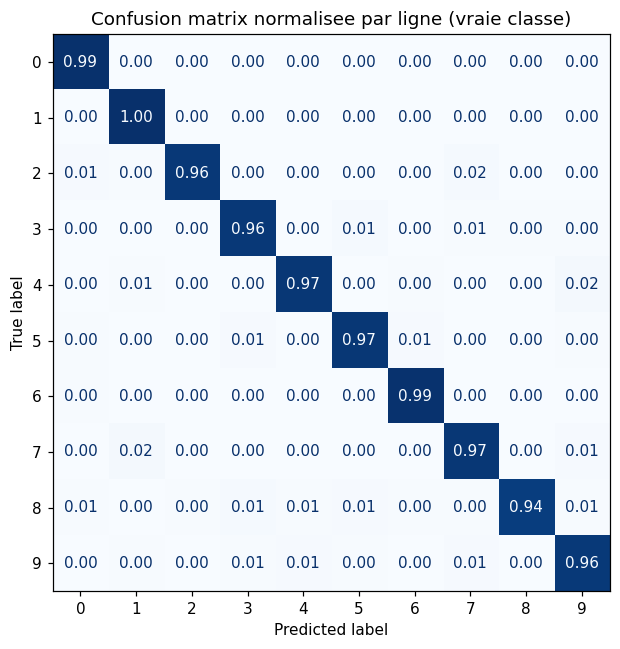

In [59]:
fig, ax = plt.subplots(figsize=(6.5, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    normalize="true",
    values_format=".2f",
    cmap="Blues",
    colorbar=False,
    ax=ax,
)
ax.set_title("Confusion matrix normalisee par ligne (vraie classe)")
plt.tight_layout()
plt.show()

Normaliser **par ligne** (`normalize="true"`) donne, pour chaque vraie classe, la répartition des
prédictions. La diagonale est alors le **recall** de chaque classe :

$$\text{recall}_{k} = \frac{TP_{k}}{TP_{k} + FN_{k}}$$

### Trou 8 — classer les confusions

`confusion_matrix(y_test, y_pred)[i, j]` donne le nombre d'exemples de vraie classe $i$ prédits en
classe $j$. La **diagonale** contient les bonnes réponses ; tout le reste, les erreurs.

In [72]:
cm = confusion_matrix(y_test, y_pred)
cm_erreurs = cm.copy()

# TODO (trou 8a) - Annuler la diagonale de cm_erreurs pour ne garder que les erreurs.
#   Indice : NumPy a une fonction qui remplit la diagonale d'un tableau 2D.
print(cm.shape)
a,b = cm_erreurs.shape

for i in range(a):
    for j in range(b):
        if i==j:
            cm_erreurs[i,j]=0


# TODO (trou 8b) - Construire la liste des erreurs sous forme de triplets
#   (nombre, vraie_classe, classe_predite), triee du plus frequent au moins frequent,
#   en ignorant les cases a zero.

erreurs = [(cm_erreurs[i, j], i, j)  for i in range(10) for j in range(10) if cm_erreurs[i, j]>0]
erreurs.sort(reverse=True)

print("Les 10 confusions les plus frequentes :\n")
for compte, vrai, predit in erreurs[:10]:
    print(f"  un {vrai} classe en {predit} : {compte} fois")

(10, 10)
Les 10 confusions les plus frequentes :

  un 4 classe en 9 : 19 fois
  un 7 classe en 1 : 17 fois
  un 2 classe en 7 : 16 fois
  un 8 classe en 3 : 14 fois
  un 3 classe en 5 : 14 fois
  un 8 classe en 5 : 11 fois
  un 9 classe en 7 : 10 fois
  un 7 classe en 9 : 10 fois
  un 2 classe en 0 : 10 fois
  un 9 classe en 4 : 9 fois


In [73]:
# Verification - ne modifiez pas cette cellule
assert cm_erreurs.trace() == 0, "la diagonale de cm_erreurs doit etre nulle"
assert cm.trace() > 9000, "cm d'origine ne doit PAS etre modifiee (travaillez sur la copie)"
assert len(erreurs) > 0, "erreurs ne doit pas etre vide"
assert all(len(t) == 3 for t in erreurs), "chaque element doit etre un triplet"
assert all(c > 0 for c, _, _ in erreurs), "les cases a zero doivent etre exclues"
assert all(v != p for _, v, p in erreurs), "la diagonale doit etre exclue"
comptes = [c for c, _, _ in erreurs]
assert comptes == sorted(comptes, reverse=True), "la liste doit etre triee par ordre decroissant"
assert sum(comptes) == (y_test != y_pred).sum(), \
    "la somme des erreurs doit egaler le nombre total de mauvaises predictions"
print("Trou 8 : OK -", sum(comptes), "erreurs au total")

Trou 8 : OK - 286 erreurs au total


19 images de '4' classees en '9'


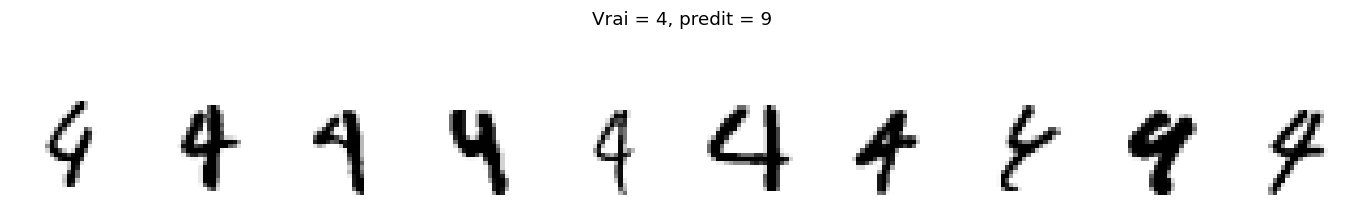

In [74]:
# Visualisation de la confusion la plus frequente
_, VRAI, PREDIT = erreurs[0]

masque = (y_test == VRAI) & (y_pred == PREDIT)
images = X_test[masque]
print(f"{len(images)} images de '{VRAI}' classees en '{PREDIT}'")

n_show = min(10, len(images))
fig, axes = plt.subplots(1, n_show, figsize=(1.25 * n_show, 1.9))
for ax, img in zip(np.atleast_1d(axes), images[:n_show]):
    ax.imshow(img.reshape(28, 28), cmap="binary")
    ax.axis("off")
fig.suptitle(f"Vrai = {VRAI}, predit = {PREDIT}", y=1.06)
plt.tight_layout()
plt.show()

Regardez ces images une par une et posez-vous la question du point **BHD-18** : s'agit-il d'une
erreur du modèle, ou de l'**irreducible error** ?

Beaucoup de ces chiffres sont illisibles pour un humain aussi. Dans ce cas, aucun réglage
d'hyperparamètre ne les récupérera. Il faudrait changer de **représentation** (c'est le sujet de
l'exercice 2) ou de **famille de modèles** (un CNN, phase 2 du carnet).

---
## 11. Bilan

### Ce qu'il faut retenir

| Constat | Pourquoi |
|---|---|
| Le `fit` du k-NN est gratuit, le `predict` est cher | C'est un **non-parametric algorithm** : il garde tout le training set au lieu de le résumer |
| `weights="distance"` bat `"uniform"` | Pondérer par $1/\lVert x - x^{(i)} \rVert_{2}$ évite les égalités et respecte la proximité réelle |
| Le k-NN excelle sur MNIST | Images centrées et normalisées : la distance euclidienne pixel à pixel a un sens |
| $97{,}1\ \% \pm 0{,}33$ point | Sur 10 000 exemples de test, la troisième décimale est du bruit |
| On valide le code avant de lancer la grille | Deux minutes investies, quarante économisées |

### Auto-évaluation

Reprenez ces questions **sans rouvrir le notebook**. Si vous butez, le point est encore « Compris »
et pas « Maîtrisé ».

1. Pourquoi le `predict` d'un k-NN est-il plus lent que son `fit` ?
2. Que change `weights="distance"` par rapport à `"uniform"`, et pourquoi est-ce utile avec $k=4$ ?
3. Pourquoi ne règle-t-on jamais un hyperparamètre sur le test set ?
4. Sur 10 000 exemples de test, quel écart minimal entre deux modèles est significatif ?
5. Que vaut la diagonale d'une confusion matrix normalisée par ligne ?

### Rattachement au carnet

- **B13-6** : jamais régler un hyperparamètre sur le test set.
- **B14-9** : ici les classes sont équilibrées, donc l'accuracy suffit — cas rare.
- **B17-14** : confusion matrix, recall par classe.
- **B17-15** : k-nearest neighbors, non-parametric, curse of dimensionality.
- **B03-13** : intervalle de confiance d'une proportion mesurée.
- **BHD-12** : deux scores proches ne se classent pas.
- **BHD-18** : error analysis, irreducible error.

### Suite

`B14_ex2_data_augmentation_exercice.ipynb` reprend ce modèle comme baseline et lui ajoute une
connaissance du domaine. Faites les deux d'affilée.